In [1]:
import pandas as pd
 
white_wine = pd.read_csv("data/winequality-white.csv", sep=";")
red_wine = pd.read_csv("data/winequality-red.csv", sep=",")

In [2]:
white_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
red_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
red_wine['is_red'] = 1
white_wine['is_red'] = 0
 
data = pd.concat([red_wine, white_wine], axis=0)
 
# Remove spaces from column names
data.rename(columns=lambda x: x.replace(' ', '_'), inplace=True)

In [5]:
data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


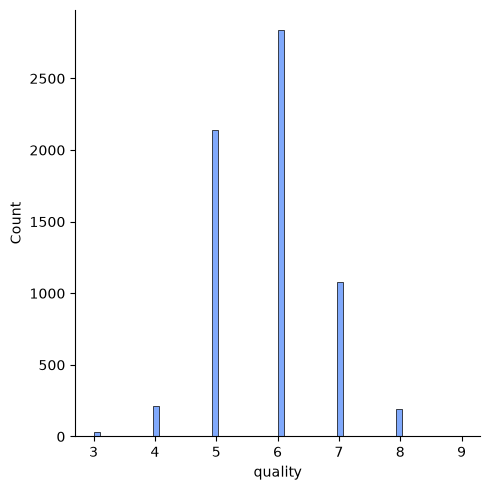

In [7]:
import seaborn as sns
sns.displot(data.quality, kde=False);

Looks like quality scores are normally distributed between 3 and 9.

Define a wine as high quality if it has quality >= 7.

In [8]:
high_quality = (data.quality >= 7).astype(int)
data.quality = high_quality

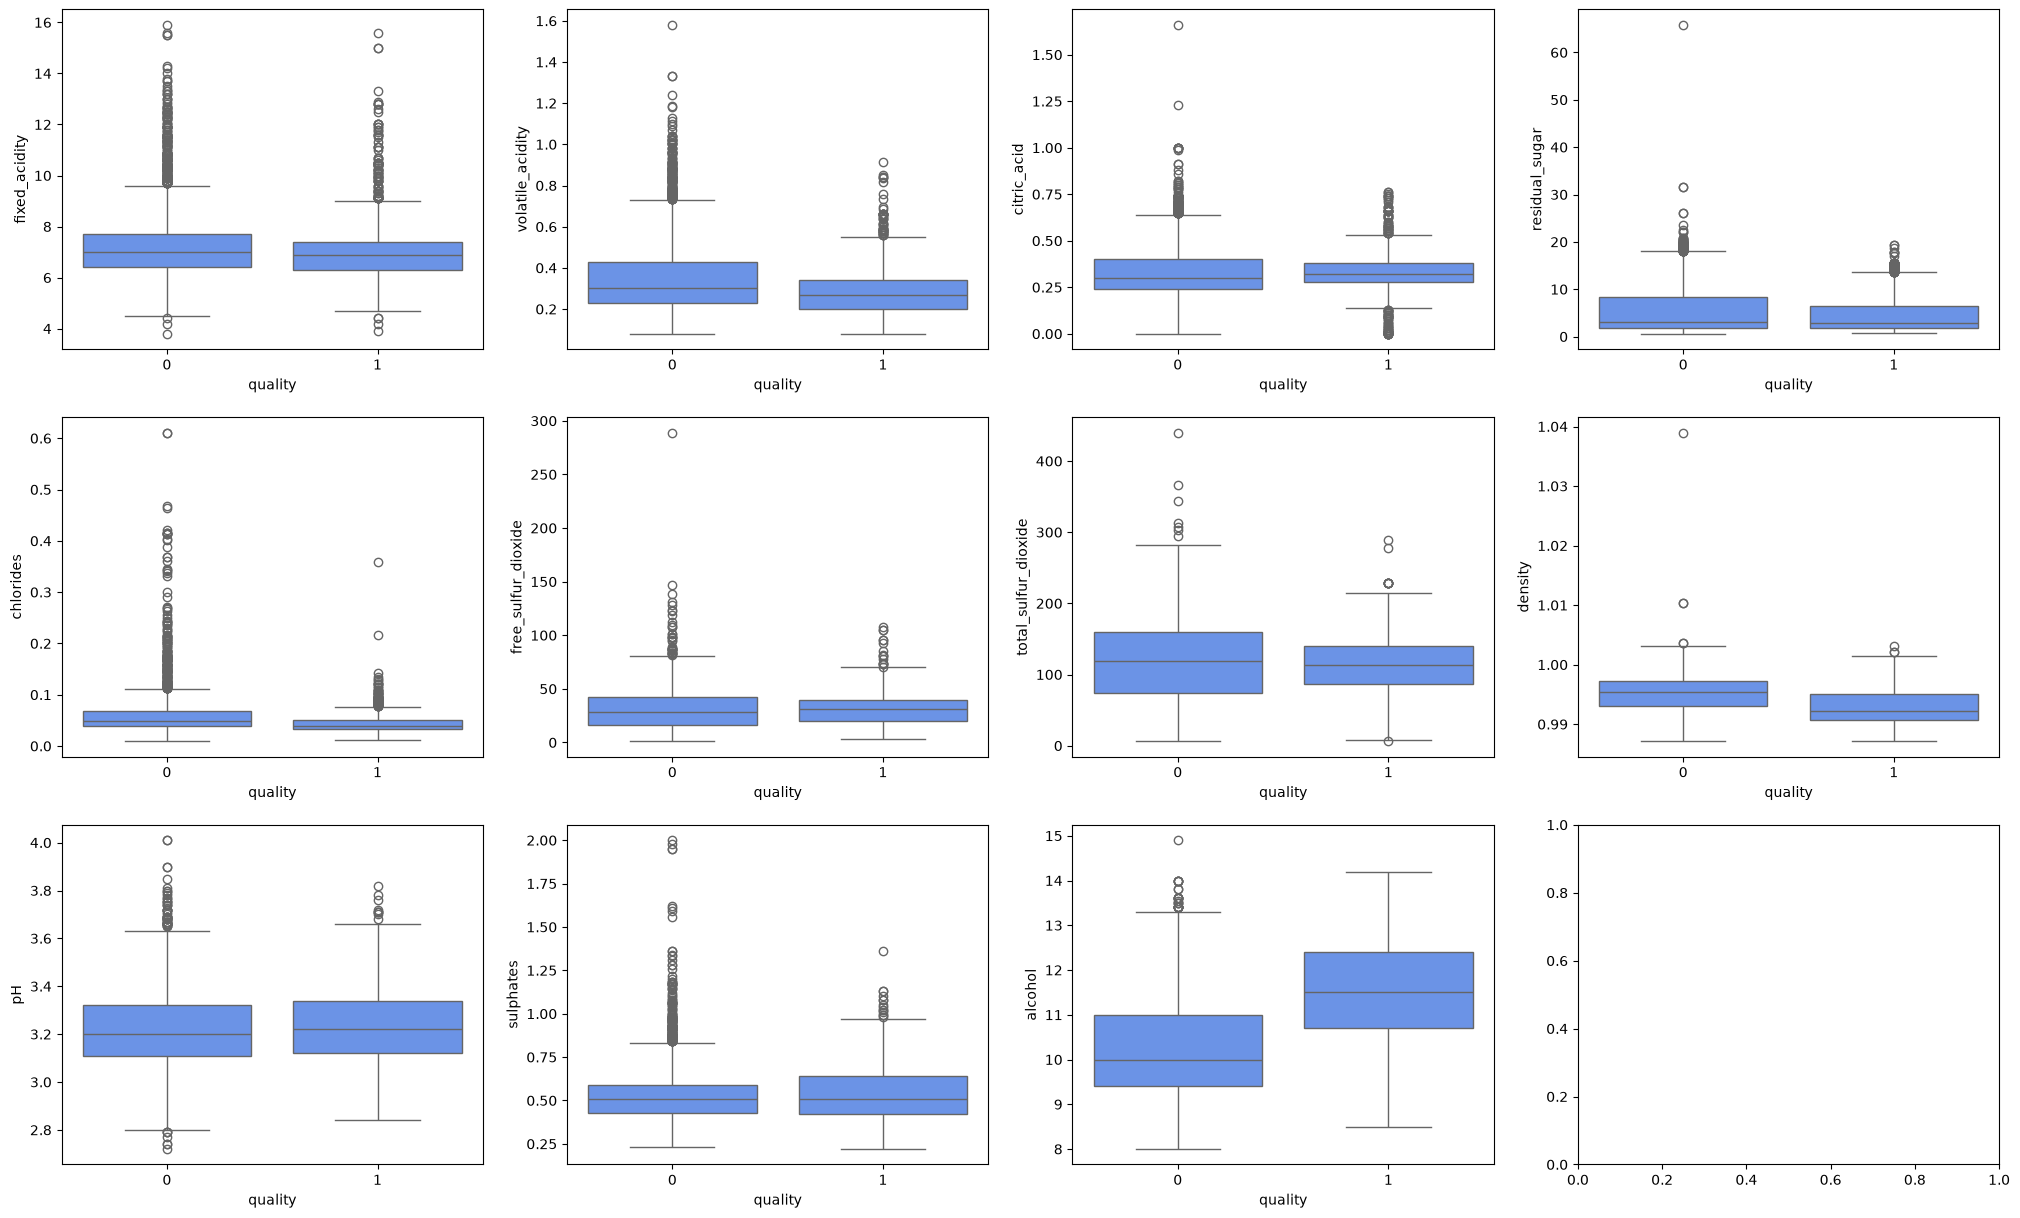

In [9]:
import matplotlib.pyplot as plt
 
dims = (3, 4)
 
f, axes = plt.subplots(dims[0], dims[1], figsize=(25, 15))
axis_i, axis_j = 0, 0
for col in data.columns:
  if col == 'is_red' or col == 'quality':
    continue # Box plots cannot be used on indicator variables
  sns.boxplot(x=high_quality, y=data[col], ax=axes[axis_i, axis_j])
  axis_j += 1
  if axis_j == dims[1]:
    axis_i += 1
    axis_j = 0

In the above box plots, a few variables stand out as good univariate predictors of quality.

In the alcohol box plot, the median alcohol content of high quality wines is greater than even the 75th quantile of low quality wines. High alcohol content is correlated with quality.
In the density box plot, low quality wines have a greater density than high quality wines. Density is inversely correlated with quality.

In [10]:
data.isna().any()


fixed_acidity           False
volatile_acidity        False
citric_acid             False
residual_sugar          False
chlorides               False
free_sulfur_dioxide     False
total_sulfur_dioxide    False
density                 False
pH                      False
sulphates               False
alcohol                 False
quality                 False
is_red                  False
dtype: bool

In [11]:
from sklearn.model_selection import train_test_split
 
X = data.drop(["quality"], axis=1)
y = data.quality
 
# Split out the training data
X_train, X_rem, y_train, y_rem = train_test_split(X, y, train_size=0.6, random_state=123)
 
# Split the remaining data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(X_rem, y_rem, test_size=0.5, random_state=123)

### Build a baseline model

This task seems well suited to a random forest classifier, since the output is binary and there may be interactions between multiple variables.

The following code builds a simple classifier using scikit-learn. It uses MLflow to keep track of the model accuracy, and to save the model for later use.

In [12]:
import mlflow
import mlflow.pyfunc
import mlflow.sklearn
import numpy as np
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from mlflow.models.signature import infer_signature
from mlflow.utils.environment import _mlflow_conda_env
import cloudpickle
import time
 
# The predict method of sklearn's RandomForestClassifier returns a binary classification (0 or 1). 
# The following code creates a wrapper function, SklearnModelWrapper, that uses 
# the predict_proba method to return the probability that the observation belongs to each class. 
 
class SklearnModelWrapper(mlflow.pyfunc.PythonModel):
  def __init__(self, model):
    self.model = model
    
  def predict(self, context, model_input):
    return self.model.predict_proba(model_input)[:,1]


# mlflow.start_run creates a new MLflow run to track the performance of this model. 
# Within the context, you call mlflow.log_param to keep track of the parameters used, and
# mlflow.log_metric to record metrics like accuracy.
with mlflow.start_run(run_name='untuned_random_forest'):
    n_estimators = 10
    model = RandomForestClassifier(n_estimators=n_estimators, random_state=np.random.RandomState(123))
    model.fit(X_train, y_train)

    # predict_proba returns [prob_negative, prob_positive], so slice the output with [:, 1]
    predictions_test = model.predict_proba(X_test)[:,1]
    auc_score = roc_auc_score(y_test, predictions_test)
    mlflow.log_param('n_estimators', n_estimators)
    # Use the area under the ROC curve as a metric.
    mlflow.log_metric('auc', auc_score)
    wrappedModel = SklearnModelWrapper(model)
    # Log the model with a signature that defines the schema of the model's inputs and outputs. 
    # When the model is deployed, this signature will be used to validate inputs.
    signature = infer_signature(X_train, wrappedModel.predict(None, X_train))
    
    # MLflow contains utilities to create a conda environment used to serve models.
    # The necessary dependencies are added to a conda.yaml file which is logged along with the model.
    conda_env =  _mlflow_conda_env(
            additional_conda_deps=None,
            additional_pip_deps=["cloudpickle=={}".format(cloudpickle.__version__), "scikit-learn=={}".format(sklearn.__version__)],
            additional_conda_channels=None,
        )
    mlflow.pyfunc.log_model("random_forest_model",
                            python_model=wrappedModel,
                            conda_env=conda_env,
                            signature=signature)

/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/10/18 17:38:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 17:38:28 INFO mlflow.store.db.utils: Updating database tables
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema con

In [13]:
feature_importances = pd.DataFrame(model.feature_importances_, index=X_train.columns.tolist(), columns=['importance'])
feature_importances.sort_values('importance', ascending=False)

,importance
alcohol,0.158153
density,0.120193
volatile_acidity,0.093647
chlorides,0.086331
residual_sugar,0.082721
free_sulfur_dioxide,0.080434
total_sulfur_dioxide,0.078323
pH,0.076663
sulphates,0.074954
citric_acid,0.074324


As illustrated by the boxplots shown previously, both alcohol and density are important in predicting quality.

You logged the Area Under the ROC Curve (AUC) to MLflow. Click Experiment at the upper right to display the Experiment Runs sidebar.

The model achieved an AUC of 0.854.

A random classifier would have an AUC of 0.5, and higher AUC values are better. For more information, see Receiver Operating Characteristic Curve.

Register the model in MLflow Model Registry
By registering this model in Model Registry, you can easily reference the model from anywhere within Databricks.

The following section shows how to do this programmatically, but you can also register a model using the UI. See "Create or register a model using the UI" (AWS|Azure|GCP).

In [14]:
run_id = mlflow.search_runs(filter_string='tags.mlflow.runName = "untuned_random_forest"').iloc[0].run_id

In [15]:
run_id

'6d0c757347494012b22d2375c02971e7'

In [16]:
# If you see the error "PERMISSION_DENIED: User does not have any permission level assigned to the registered model", 
# the cause may be that a model already exists with the name "wine_quality". Try using a different name.
model_name = "wine_quality"
model_version = mlflow.register_model(f"runs:/{run_id}/random_forest_model", model_name)
 
# Registering the model takes a few seconds, so add a small delay
time.sleep(15)

Successfully registered model 'wine_quality'.
2026/10/18 17:38:43 WARNING mlflow.tracking._model_registry.fluent: Run with id 6d0c757347494012b22d2375c02971e7 has no artifacts at artifact path 'random_forest_model', registering model based on models:/m-c1fcaf17cf7843818ebadc50cf495f72 instead
Created version '1' of model 'wine_quality'.


In [17]:
"""
The MlflowClient class allows you to interact with the MLflow Tracking Server programmatically. 
You can use it to perform various tasks, such as creating and managing experiments, starting 
and managing runs, logging metrics and parameters, and querying information about experiments and runs.

"""
from mlflow.tracking import MlflowClient
client = MlflowClient()

client.transition_model_version_stage(
  name=model_name,
  version=model_version.version,
  stage="Production",
)

/var/folders/gk/j0fcksg94558m2frddxyj2lw0000gn/T/ipykernel_25304/2553610896.py:10: FutureWarning: ``mlflow.tracking.client.MlflowClient.transition_model_version_stage`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  client.transition_model_version_stage(


<ModelVersion: aliases=[], creation_timestamp=1792359523667, current_stage='Production', deployment_job_state=None, description=None, last_updated_timestamp=1792359555876, metrics=None, model_id=None, name='wine_quality', params=None, run_id='6d0c757347494012b22d2375c02971e7', run_link=None, source='models:/m-c1fcaf17cf7843818ebadc50cf495f72', status='READY', status_message=None, tags={}, user_id=None, version=1, workspace='default'>

The Models page now shows the model version in stage "Production".

You can now refer to the model using the path "models:/wine_quality/production".

In [18]:
model = mlflow.pyfunc.load_model(f"models:/{model_name}/production")
 
# Sanity-check: This should match the AUC logged by MLflow
print(f'AUC: {roc_auc_score(y_test, model.predict(X_test))}')
AUC: 0.8540300975814177

AUC: 0.8539084949712643


In [19]:
!mlflow ui --port=5001

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/18 17:39:23 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/18 17:39:23 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/18 17:39:23 INFO:     Uvicorn running on http://127.0.0.1:5001 (Press CTRL+C to quit)
2026/10/18 17:39:23 INFO:     Started parent process [25841]
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from star

## Experiment with a new model

The random forest model performed well even without hyperparameter tuning.

The following code uses the xgboost library to train a more accurate model. It runs a parallel hyperparameter sweep to train multiple models in parallel, using Hyperopt and SparkTrials. As before, the code tracks the performance of each parameter configuration with MLflow.

In [20]:
# hyperopt library imports for defining and executing hyperparameter optimization
from hyperopt import fmin, tpe, hp, SparkTrials, Trials, STATUS_OK  
# scope is used for casting hyperopt variables to int when needed (like max_depth)
from hyperopt.pyll import scope  
# math.exp is a mathematical function for calculating exponential values
from math import exp  
# mlflow.xgboost is used to log XGBoost model parameters, metrics, and models with MLflow
import mlflow.xgboost  
import numpy as np  
# xgboost is an implementation of gradient boosted decision trees designed for speed and performance
import xgboost as xgb  

# search_space dictionary defines the range and distribution of hyperparameters for the model
search_space = {
  'max_depth': scope.int(hp.quniform('max_depth', 4, 100, 1)),  # Integer range for tree depth
  'learning_rate': hp.loguniform('learning_rate', -3, 0),  # Log-uniform distribution for learning rate
  'reg_alpha': hp.loguniform('reg_alpha', -5, -1),  # Log-uniform for L1 regularization term
  'reg_lambda': hp.loguniform('reg_lambda', -6, -1),  # Log-uniform for L2 regularization term
  'min_child_weight': hp.loguniform('min_child_weight', -1, 3),  # Log-uniform for minimum sum of instance weight(hessian) needed in a child
  'objective': 'binary:logistic',  # Objective function for binary classification
  'seed': 123,  # Set a seed for deterministic training
}



Nested Runs: When you use mlflow.start_run(nested=True) within the main run, you create nested runs. These runs are associated with the main run and inherit some of its parameters and context. Nested runs are typically used to explore variations or sub-experiments within the main experiment.

python
Copy code
import mlflow

with mlflow.start_run():
    # Your main experiment code goes here

    with mlflow.start_run(nested=True):
        # Nested experiment code goes here
Parameters and metrics logged in the nested run are associated with that specific run and can be accessed separately from the main run.
You can create multiple nested runs within a main run to represent different variations or configurations of your experiment.
python
Copy code
import mlflow

with mlflow.start_run():
    # Your main experiment code goes here

    with mlflow.start_run(nested=True):
        # Nested experiment code 1 goes here

    with mlflow.start_run(nested=True):
        # Nested experiment code 2 goes here

In [21]:
def train_model(params):
      # With MLflow autologging, hyperparameters and the trained model are automatically logged to MLflow.
    mlflow.xgboost.autolog()
    with mlflow.start_run(nested=True):
        train = xgb.DMatrix(data=X_train, label=y_train)
        validation = xgb.DMatrix(data=X_val, label=y_val)
        # Pass in the validation set so xgb can track an evaluation metric. XGBoost terminates training when the evaluation metric
        # is no longer improving.
        booster = xgb.train(params=params, dtrain=train, num_boost_round=1000,\
                            evals=[(validation, "validation")], early_stopping_rounds=50)
        validation_predictions = booster.predict(validation)
        auc_score = roc_auc_score(y_val, validation_predictions)
        mlflow.log_metric('auc', auc_score)

        signature = infer_signature(X_train, booster.predict(train))
        mlflow.xgboost.log_model(booster, "model", signature=signature)

        # Set the loss to -1*auc_score so fmin maximizes the auc_score
        return {'status': STATUS_OK, 'loss': -1*auc_score, 'booster': booster.attributes()}


In [22]:
# !python3 -m pip install pyspark

In [23]:
# Importing pyspark, the Python API for Spark which lets you write Spark applications using Python
import pyspark  
# Importing specific Spark classes to manage configurations and the Spark context
from pyspark import SparkContext, SparkConf  

# Setting up the configuration for Spark:
conf_spark = SparkConf().set("spark.driver.host", "127.0.0.1")  # Configures the Spark driver host address to localhost

# Creating a SparkContext using the above configuration, essential for connecting to a Spark cluster:
sc = SparkContext(conf=conf_spark)  # Initializes the main entry point for Spark functionality


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/18 17:46:35 WARN Utils: Your hostname, Ds-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 10.110.85.160 instead (on interface en0)
26/10/18 17:46:35 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/18 17:46:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [24]:
import pyspark

TPE stands for Tree-structured Parzen Estimator. It's a Bayesian optimization technique that models the probability distribution of the hyperparameters given the observed metrics. It is particularly effective for high-dimensional spaces and has become a popular choice in machine learning for hyperparameter tuning.


In [25]:
# Greater parallelism will lead to speedups, but a less optimal hyperparameter sweep. 
# A reasonable value for parallelism is the square root of max_evals.
spark_trials = SparkTrials(parallelism=10)

# Run fmin within an MLflow run context so that each hyperparameter configuration is logged as a child run of a parent
# run called "xgboost_models" .
with mlflow.start_run(run_name='xgboost_models'):
  best_params = fmin(
    fn=train_model, 
    space=search_space, 
    algo=tpe.suggest,
    max_evals=96,
    trials=spark_trials,
  )

  

  0%|          | 0/96 [00:00<?, ?trial/s, best loss=?]

/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/pyspark/util.py:474: UserWarning: Spark session is not provided. Tags will not be inherited.
  warnings.warn(

]2026/10/18 17:47:13 WARNING mlflow.xgboost: Failed to log dataset information to MLflow Tracking. Reason: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID cff817e895e94b28b266dbc856e7991b. Failed operations: [MlflowException(\'(sqlite3.IntegrityError) UNIQUE constraint failed: datasets.experiment_id, datasets.name, datasets.digest\\n[SQL: INSERT INTO datasets (dataset_uuid, experiment_id, name, digest, dataset_source_type, dataset_source, dataset_schema, dataset_profile) VALUES (?, ?, ?, ?, ?, ?, ?, ?)]\\n[parameters: [(\\\'334d416818584dc4acf8f33a6b9d9037\\\', 0, \\\'dataset\\\', \\\'962ea164\\\', \\\'code\\\', \\\'{"tags": {"mlflow.user": "dgshivu", "mlflow.source.name": "/Users/d

  2%|▏         | 2/96 [00:11<08:39,  5.53s/trial, best loss: -0.8868859777404903]

/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/18 17:47:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
[0]	validation-logloss:0.45955ge 3:>    (0 + 1) / 1][Stage 4:>    (0 + 1) / 1]
[1]	validation-

  3%|▎         | 3/96 [00:12<05:39,  3.65s/trial, best loss: -0.8908152583858006]

...

 96%|█████████▌| 92/96 [01:53<00:04,  1.14s/trial, best loss: -0.9003517495112453]

/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/18 17:49:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/

 99%|█████████▉| 95/96 [01:55<00:00,  1.16trial/s, best loss: -0.9003517495112453]

100%|██████████| 96/96 [01:56<00:00,  1.21s/trial, best loss: -0.9003517495112453]

Total Trials: 96: 96 succeeded, 0 failed, 0 cancelled.


In [26]:
best_run = mlflow.search_runs(order_by=['metrics.auc DESC']).iloc[0]
print(f'AUC of Best Run: {best_run["metrics.auc"]}')

AUC of Best Run: 0.9003517495112453


## Update the production wine_quality model in MLflow Model Registry

Earlier, you saved the baseline model to Model Registry with the name wine_quality. Now that you have a created a more accurate model, update wine_quality.



In [27]:
new_model_version = mlflow.register_model(f"runs:/{best_run.run_id}/model", model_name)
 
# Registering the model takes a few seconds, so add a small delay
time.sleep(10)

Registered model 'wine_quality' already exists. Creating a new version of this model...
2026/10/18 17:49:30 WARNING mlflow.tracking._model_registry.fluent: Run with id 218051d817a145ecbf1cd415be33776d has no artifacts at artifact path 'model', registering model based on models:/m-a2aad43f915c41829dbccd18247a2892 instead
Created version '2' of model 'wine_quality'.


Click Models in the left sidebar to see that the wine_quality model now has two versions.

The following code promotes the new version to production.

In [28]:
client.transition_model_version_stage(
    name=model_name,
    version=model_version.version,
    stage='Archived'
)

client.transition_model_version_stage(
    name=model_name,
    version=new_model_version.version,
    stage='Production'
)

/var/folders/gk/j0fcksg94558m2frddxyj2lw0000gn/T/ipykernel_25304/517306411.py:1: FutureWarning: ``mlflow.tracking.client.MlflowClient.transition_model_version_stage`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  client.transition_model_version_stage(
/var/folders/gk/j0fcksg94558m2frddxyj2lw0000gn/T/ipykernel_25304/517306411.py:7: FutureWarning: ``mlflow.tracking.client.MlflowClient.transition_model_version_stage`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  client.transition_model_version_stage(


<ModelVersion: aliases=[], creation_timestamp=1792360170243, current_stage='Production', deployment_job_state=None, description=None, last_updated_timestamp=1792360209256, metrics=None, model_id=None, name='wine_quality', params=None, run_id='218051d817a145ecbf1cd415be33776d', run_link=None, source='models:/m-a2aad43f915c41829dbccd18247a2892', status='READY', status_message=None, tags={}, user_id=None, version=2, workspace='default'>

Clients that call load_model now receive the new model.



In [29]:
model = mlflow.pyfunc.load_model(f"models:/{model_name}/production")
print(f"AUC: {roc_auc_score(y_test, model.predict(X_test))}")

AUC: 0.9073201029693487


## Batch inference

There are many scenarios where you might want to evaluate a model on a corpus of new data. For example, you may have a fresh batch of data, or may need to compare the performance of two models on the same corpus of data.

The following code evaluates the model on data stored in a Delta table, using Spark to run the computation in parallel.

In [30]:
mlflow.pyfunc.spark_udf?


In [31]:
import mlflow.pyfunc

from pyspark.sql import SparkSession

# Create or retrieve a Spark session
spark = SparkSession.builder \
    .appName("MLflow Integration") \
    .config("spark.some.config.option", "config-value") \
    .getOrCreate()

apply_model_udf = mlflow.pyfunc.spark_udf(spark, f"models:/{model_name}/production")

26/10/18 17:50:31 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
2026/10/18 17:50:31 WARNING mlflow.pyfunc: Calling `spark_udf()` with `env_manager="local"` does not recreate the same environment that was used during training, which may lead to errors or inaccurate predictions. We recommend specifying `env_manager="conda"`, which automatically recreates the environment that was used to train the model and performs inference in the recreated environment.
2026/10/18 17:50:31 INFO mlflow.models.flavor_backend_registry: Selected backend for flavor 'python_function'
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/py

In [32]:
# new_data = spark.read.format("csv").load(table_path) # table_path is path to the delta table

In [33]:
new_model_version

<ModelVersion: aliases=[], creation_timestamp=1792360170243, current_stage='None', deployment_job_state=None, description=None, last_updated_timestamp=1792360170243, metrics=None, model_id=None, name='wine_quality', params=None, run_id='218051d817a145ecbf1cd415be33776d', run_link=None, source='models:/m-a2aad43f915c41829dbccd18247a2892', status='READY', status_message=None, tags={}, user_id=None, version=2, workspace='default'>

In [34]:
new_model_version.run_id

'218051d817a145ecbf1cd415be33776d'

In [35]:
# Serve the model using the MLflow Model Serving

# Run the following in terminal outiside jupyter and after activating the virtual environment
# mlflow models serve --env-manager=local -m models:/wine_quality/production -h 0.0.0.0 -p 5001

- Here **model_name** is `wine_quality`

In [36]:
import requests
import json

url = 'http://localhost:5001/invocations'

datads_dict = {"dataframe_split": X_test.to_dict(orient='split')}

response = requests.post(url, json=datads_dict)
predictions = response.json()

print(predictions)

ConnectionError: HTTPConnectionPool(host='localhost', port=5001): Max retries exceeded with url: /invocations (Caused by NewConnectionError("HTTPConnection(host='localhost', port=5001): Failed to establish a new connection: [Errno 61] Connection refused"))

In [37]:
!mlflow ui

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/18 17:50:46 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/18 17:50:46 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/18 17:50:46 INFO:     Uvicorn running on http://127.0.0.1:5000 (Press CTRL+C to quit)
2026/10/18 17:50:46 INFO:     Started parent process [28883]
/Users/dgshivu/Documents/lair/NEU/IE 7374/labs/lab2/.venv/lib/python3.12/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from star